### Importando as Bibliotecas

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

def drop_reset_index(df):
    df = df.dropna()
    df = df.reset_index(drop=True)
    df.index += 1
    return df

def plot_profit_acu(dataframe, title_text):
    dataframe['Profit_acu'] = dataframe.Profit.cumsum()
    n_apostas = dataframe.shape[0]
    profit = round(dataframe.Profit_acu.tail(1).item(), 2)
    # ROI = round((dataframe.Profit_acu.tail(1) / n_apostas * 100).item(), 2)
    dataframe['Investimento_acu'] = dataframe.Investimento.cumsum()
    ROI = round(((dataframe.Profit_acu.tail(1) / dataframe.Investimento_acu.tail(1)) * 100).item(), 2)
    drawdown = dataframe['Profit_acu'] - dataframe['Profit_acu'].cummax()
    drawdown_maximo = round(drawdown.min(), 2)
    winrate_medio = round((dataframe['Profit'] > 0).mean() * 100, 2)
    desvio_padrao = round(dataframe['Profit'].std(), 2)
    dataframe.Profit_acu.plot(title=title_text, xlabel='Entradas', ylabel='Stakes')
    print("Metodo:",title_text)
    print("Profit:", profit, "stakes em", n_apostas, "jogos")
    print("ROI:", ROI, "%")
    print("Drawdown Maximo Acumulado:", drawdown_maximo)
    print("Winrate Medio:", winrate_medio, "%")
    print("Desvio Padrao:", desvio_padrao)
    print("")

In [2]:
def rename_leagues(df):
    df.replace('Argentinian Copa de la Liga Profesional','ARGENTINA - COPA DE LA LIGA PROFESIONAL', inplace=True)
    df.replace('Argentinian Primera Division','ARGENTINA - LIGA PROFESIONAL', inplace=True)
    df.replace('Armenian Premier League','ARMENIA - PREMIER LEAGUE', inplace=True)
    df.replace('Australian A-League Men','AUSTRALIA - A-LEAGUE', inplace=True)
    df.replace('Austrian Bundesliga','AUSTRIA - 2. LIGA', inplace=True)
    df.replace('Austrian Erste Liga','AUSTRIA - BUNDESLIGA', inplace=True)
    df.replace('Belgian First Division B','BELGIUM - CHALLENGER PRO LEAGUE', inplace=True)
    df.replace('Belgian First Division A','BELGIUM - JUPILER PRO LEAGUE', inplace=True)
    df.replace('Bolivian Liga de Futbol Profesional','BOLIVIA - DIVISION PROFESIONAL', inplace=True)
    df.replace('Bosnian Premier League','BOSNIA AND HERZEGOVINA - PREMIJER LIGA BIH', inplace=True)
    df.replace('Brazilian Serie A','BRAZIL - SERIE A', inplace=True)
    df.replace('Brazilian Serie B','BRAZIL - SERIE B', inplace=True)
    df.replace('Brazilian Serie C','BRAZIL - SERIE C', inplace=True)
    df.replace('Brazilian Serie D','BRAZIL - SERIE D', inplace=True)
    df.replace('Bulgarian A League','BULGARIA - PARVA LIGA', inplace=True)
    df.replace('Chilean Primera Division','CHILE - PRIMERA DIVISION', inplace=True)
    df.replace('Chinese Super League','CHINA - SUPER LEAGUE', inplace=True)
    df.replace('Colombian Primera A','COLOMBIA - PRIMERA A', inplace=True)
    df.replace('Croatian 1 HNL','CROATIA - HNL', inplace=True)
    df.replace('Croatian 2 HNL','CROATIA - PRVA NL', inplace=True)
    df.replace('Cypriot 1st Division','CYPRUS - CYTA CHAMPIONSHIP', inplace=True)
    df.replace('Czech 1 Liga','CZECH REPUBLIC - FORTUNA LIGA', inplace=True)
    df.replace('Danish 1st Division','DENMARK - 1ST DIVISION', inplace=True)
    df.replace('Danish Superliga','DENMARK - SUPERLIGA', inplace=True)
    df.replace('Ecuadorian Serie A','ECUADOR - LIGA PRO', inplace=True)
    df.replace('Egyptian Premier','EGYPT - PREMIER LEAGUE', inplace=True)
    df.replace('English Championship','ENGLAND - CHAMPIONSHIP', inplace=True)
    df.replace('English League 1','ENGLAND - LEAGUE ONE', inplace=True)
    df.replace('English League 2','ENGLAND - LEAGUE TWO', inplace=True)
    df.replace('English National League','ENGLAND - NATIONAL LEAGUE', inplace=True)
    df.replace('English Premier League','ENGLAND - PREMIER LEAGUE', inplace=True)
    df.replace('Estonian Esiliiga','ESTONIA - ESILIIGA', inplace=True)
    df.replace('Estonian Premier League','ESTONIA - MEISTRILIIGA', inplace=True)
    df.replace('UEFA Champions League','EUROPE - CHAMPIONS LEAGUE', inplace=True)
    df.replace('UEFA Europa Conference League','EUROPE - EUROPA CONFERENCE LEAG', inplace=True)
    df.replace('UEFA Europa League','EUROPE - EUROPA LEAGUE', inplace=True)
    df.replace('Finnish Veikkausliiga','FINLAND - VEIKKAUSLIIGA', inplace=True)
    df.replace('Finnish Ykkonen','FINLAND - YKKONEN', inplace=True)
    df.replace('French Ligue 1','FRANCE - LIGUE 1', inplace=True)
    df.replace('French Ligue 2','FRANCE - LIGUE 2', inplace=True)
    df.replace('French National','FRANCE - NATIONAL', inplace=True)
    df.replace('German Bundesliga 2','GERMANY - 2. BUNDESLIGA', inplace=True)
    df.replace('German 3 Liga','GERMANY - 3. LIGA', inplace=True)
    df.replace('German Bundesliga','GERMANY - BUNDESLIGA', inplace=True)
    df.replace('Greek Super League','GREECE - SUPER LEAGUE', inplace=True)
    df.replace('Hungarian NB I','HUNGARY - OTP BANK LIGA', inplace=True)
    #df.replace('????','ICELAND - BESTA DEILD KARLA', inplace=True)
    df.replace('Icelandic 1 Deild','ICELAND - LENGJUDEILDIN', inplace=True)
    df.replace('Irish Division 1','IRELAND - DIVISION 1', inplace=True)
    df.replace('Irish Premier Division','IRELAND - PREMIER DIVISION', inplace=True)
    df.replace('Israeli Premier League',"ISRAEL - LIGAT HA'AL", inplace=True)
    df.replace('Italian Serie A','ITALY - SERIE A', inplace=True)
    df.replace('Italian Serie B','ITALY - SERIE B', inplace=True)
    df.replace('Italian Serie C','ITALY - SERIE C', inplace=True)
    df.replace('Italian Serie D','ITALY - SERIE D', inplace=True)
    df.replace('Japanese J League','JAPAN - J1 LEAGUE', inplace=True)
    df.replace('Japanese J League 2','JAPAN - J2 LEAGUE', inplace=True)
    df.replace('Mexican Liga MX','MEXICO - LIGA MX', inplace=True)
    df.replace('Dutch Eerste Divisie','NETHERLANDS - EERSTE DIVISIE', inplace=True)
    df.replace('Dutch Eredivisie','NETHERLANDS - EREDIVISIE', inplace=True)
    df.replace('Northern Irish Championship','NORTHERN IRELAND - NIFL CHAMPIO', inplace=True)
    df.replace('Northern Irish Premiership','NORTHERN IRELAND - NIFL PREMIER', inplace=True)
    df.replace('Norwegian Eliteserien','NORWAY - ELITESERIEN', inplace=True)
    df.replace('Norwegian 1st Division','NORWAY - OBOS-LIGAEN', inplace=True)
    df.replace('Paraguayan Primera Division','PARAGUAY - PRIMERA DIVISION', inplace=True)
    df.replace('Peruvian Primera Division','PERU - LIGA 1', inplace=True)
    df.replace('Polish I Liga','POLAND - DIVISION 1', inplace=True)
    df.replace('Polish Ekstraklasa','POLAND - EKSTRAKLASA', inplace=True)
    df.replace('Portuguese Primeira Liga','PORTUGAL - LIGA PORTUGAL', inplace=True)
    df.replace('Portuguese Segunda Liga','PORTUGAL - LIGA PORTUGAL 2', inplace=True)
    df.replace('Romanian Liga I','ROMANIA - LIGA 1', inplace=True)
    df.replace('Romanian Liga II','ROMANIA - LIGA 2', inplace=True)
    df.replace('Saudi Professional League','SAUDI ARABIA - SAUDI PROFESSION', inplace=True)
    df.replace('Scottish Championship','SCOTLAND - CHAMPIONSHIP', inplace=True)
    df.replace('Scottish League One','SCOTLAND - LEAGUE ONE', inplace=True)
    df.replace('Scottish League Two','SCOTLAND - LEAGUE TWO', inplace=True)
    df.replace('Scottish Premiership','SCOTLAND - PREMIERSHIP', inplace=True)
    df.replace('Serbian First League','SERBIA - PRVA LIGA', inplace=True)
    df.replace('Serbian Super League','SERBIA - SUPER LIGA', inplace=True)
    df.replace('Slovakian Super League','SLOVAKIA - NIKE LIGA', inplace=True)
    df.replace('Slovenian Premier League','SLOVENIA - PRVA LIGA', inplace=True)
    df.replace('South African Premier Division','SOUTH AFRICA - PREMIER LEAGUE', inplace=True)
    df.replace('CONMEBOL Copa Libertadores','SOUTH AMERICA - COPA LIBERTADOR', inplace=True)
    df.replace('CONMEBOL Copa Sudamericana','SOUTH AMERICA - COPA SUDAMERICA', inplace=True)
    df.replace('South Korean K League 1','SOUTH KOREA - K LEAGUE 1', inplace=True)
    df.replace('South Korean K League 2','SOUTH KOREA - K LEAGUE 2', inplace=True)
    df.replace('Spanish La Liga','SPAIN - LALIGA', inplace=True)
    df.replace('Spanish Segunda Division','SPAIN - LALIGA2', inplace=True)
    df.replace('Spanish Primera Division RFEF A','SPAIN - PRIMERA RFEF', inplace=True)
    df.replace('Spanish Primera Division RFEF B','SPAIN - PRIMERA RFEF', inplace=True)
    df.replace('Spanish Primera Division RFEF C','SPAIN - PRIMERA RFEF', inplace=True)
    df.replace('Spanish Primera Division RFEF D','SPAIN - PRIMERA RFEF', inplace=True)
    df.replace('Spanish Primera Division RFEF E','SPAIN - PRIMERA RFEF', inplace=True)
    df.replace('Spanish Primera Division RFEF F','SPAIN - PRIMERA RFEF', inplace=True)
    df.replace('Spanish Primera Division RFEF G','SPAIN - PRIMERA RFEF', inplace=True)
    df.replace('Spanish Segunda RFEF - Group 1','SPAIN - SEGUNDA RFEF', inplace=True)
    df.replace('Spanish Segunda RFEF - Group 2','SPAIN - SEGUNDA RFEF', inplace=True)
    df.replace('Spanish Segunda RFEF - Group 3','SPAIN - SEGUNDA RFEF', inplace=True)
    df.replace('Spanish Segunda RFEF - Group 4','SPAIN - SEGUNDA RFEF', inplace=True)
    df.replace('Spanish Segunda RFEF - Group 5','SPAIN - SEGUNDA RFEF', inplace=True)
    df.replace('Swedish Allsvenskan','SWEDEN - ALLSVENSKAN', inplace=True)
    df.replace('Swedish Superettan','SWEDEN - SUPERETTAN', inplace=True)
    df.replace('Swiss Challenge League','SWITZERLAND - CHALLENGE LEAGUE', inplace=True)
    df.replace('Swiss Super League','SWITZERLAND - SUPER LEAGUE', inplace=True)
    df.replace('Todas as Ligas','Todas as Ligas', inplace=True)
    df.replace('Turkish 1 Lig','TURKEY - 1. LIG', inplace=True)
    df.replace('Turkish Super League','TURKEY - SUPER LIG', inplace=True)
    df.replace('Ukrainian Premier League','UKRAINE - PREMIER LEAGUE', inplace=True)
    df.replace('Uruguayan Primera Division','URUGUAY - PRIMERA DIVISION', inplace=True)
    df.replace('US Major League Soccer','USA - MLS', inplace=True)
    df.replace('US MLS','USA - MLS', inplace=True)
    df.replace('Venezuelan Primera Division','VENEZUELA - LIGA FUTVE', inplace=True)
    df.replace('Welsh Premiership','WALES - CYMRU PREMIER', inplace=True)

### Importando a Base de Dados

In [3]:
base = pd.read_csv("https://github.com/futpythontrader/YouTube/raw/main/Bases_de_Dados/Betfair/Base_de_Dados_Betfair_Exchange_Back_Lay.csv")
base = base[['Date','League','Home','Away','Goals_H','Goals_A','Goals_Min_H','Goals_Min_A',
             'Odd_H_Back','Odd_H_Lay','Odd_A_Back','Odd_A_Lay','Odd_D_Back','Odd_D_Lay',
             'Odd_Over25_FT_Back','Odd_Under25_FT_Back','Odd_BTTS_Yes_Back','Odd_BTTS_No_Back',
             'Odd_CS_0x0_Lay','Odd_CS_0x1_Lay','Odd_CS_1x0_Lay','Odd_CS_Goleada_H_Lay','Odd_CS_Goleada_A_Lay']]
base.columns = ['Date','League','Home','Away','Goals_H','Goals_A','Goals_Min_H','Goals_Min_A',
                'Odd_H','Odd_H_Lay','Odd_A','Odd_A_Lay','Odd_D','Odd_D_Lay',
                'Odd_Over25','Odd_Under25','Odd_BTTS_Yes','Odd_BTTS_No',
                'Odd_0x0','Odd_0x1','Odd_1x0','Odd_Gol_H','Odd_Gol_A']
base = drop_reset_index(base)

In [4]:
leagues = base.sort_values(by='League')
leagues = leagues['League'].unique()
leagues

array(['ARGENTINA - COPA DE LA LIGA PROFESIONAL',
       'ARGENTINA - LIGA PROFESIONAL', 'ARMENIA - PREMIER LEAGUE',
       'AUSTRALIA - A-LEAGUE', 'BELGIUM - CHALLENGER PRO LEAGUE',
       'BELGIUM - JUPILER PRO LEAGUE', 'BOLIVIA - DIVISION PROFESIONAL',
       'BRAZIL - SERIE A', 'BRAZIL - SERIE B', 'BRAZIL - SERIE C',
       'BRAZIL - SERIE D', 'BULGARIA - PARVA LIGA',
       'CHILE - PRIMERA DIVISION', 'CHINA - SUPER LEAGUE',
       'COLOMBIA - PRIMERA A', 'CROATIA - HNL', 'CROATIA - PRVA NL',
       'DENMARK - 1ST DIVISION', 'DENMARK - SUPERLIGA',
       'ECUADOR - LIGA PRO', 'EGYPT - PREMIER LEAGUE',
       'ENGLAND - CHAMPIONSHIP', 'ENGLAND - LEAGUE ONE',
       'ENGLAND - LEAGUE TWO', 'ENGLAND - NATIONAL LEAGUE',
       'ENGLAND - PREMIER LEAGUE', 'ESTONIA - ESILIIGA',
       'ESTONIA - MEISTRILIIGA', 'EUROPE - CHAMPIONS LEAGUE',
       'EUROPE - EUROPA LEAGUE', 'FINLAND - VEIKKAUSLIIGA',
       'FINLAND - YKKONEN', 'FRANCE - LIGUE 1', 'FRANCE - LIGUE 2',
       'FRANCE - NATIO

### Criação de Variáveis

In [5]:
df = base.copy()

df['VAR01'] = np.abs(df['Odd_H'] - df['Odd_A'])
df['VAR02'] = np.abs(df['Odd_H'] - df['Odd_D'])
df['VAR03'] = np.abs(df['Odd_D'] - df['Odd_A'])
df['VAR04'] = np.degrees(np.arctan((df['Odd_A'] - df['Odd_H']) / 2))
df['VAR05'] = np.degrees(np.arctan((df['Odd_D'] - df['Odd_H']) / 2))
df['VAR06'] = np.degrees(np.arctan((df['Odd_A'] - df['Odd_D']) / 2))
df['VAR07'] = np.abs((df['Odd_H'] - df['Odd_A'])) / df['Odd_A']
df['VAR08'] = np.abs((df['Odd_H'] - df['Odd_D'])) / df['Odd_D']
df['VAR09'] = np.abs((df['Odd_D'] - df['Odd_A'])) / df['Odd_A']

In [6]:
df['Back_Home'] = np.where((df['Goals_H'] >  df['Goals_A']), 1, 0)
df['Profit_Back_Home'] = np.where((df['Back_Home'] == 1), df['Odd_H']-1, -1)

df['Back_Draw'] = np.where((df['Goals_H'] == df['Goals_A']), 1, 0)
df['Profit_Back_Draw'] = np.where((df['Back_Draw'] == 1), df['Odd_D']-1, -1)

df['Back_Away'] = np.where((df['Goals_H']  < df['Goals_A']), 1, 0)
df['Profit_Back_Away'] = np.where((df['Back_Away'] == 1), df['Odd_A']-1, -1)

df['Lay_Home'] = np.where((df['Goals_H'] >  df['Goals_A']), 0, 1)
df['Profit_Lay_Home'] = np.where((df['Lay_Home'] == 1), 0.94/(df['Odd_H_Lay']-1), -1)

df['Lay_Draw'] = np.where((df['Goals_H'] == df['Goals_A']), 0, 1)
df['Profit_Lay_Draw'] = np.where((df['Lay_Draw'] == 1), 0.94/(df['Odd_D_Lay']-1), -1)

df['Lay_Away'] = np.where((df['Goals_H']  < df['Goals_A']), 0, 1)
df['Profit_Lay_Away'] = np.where((df['Lay_Away'] == 1), 0.94/(df['Odd_A_Lay']-1), -1)

df['Over25'] = np.where((df['Goals_H'] + df['Goals_A']) > 2, 1, 0)
df['Profit_Over25'] = np.where((df['Over25'] == 1), df['Odd_Over25']-1, -1)

df['Under25'] = np.where((df['Goals_H'] + df['Goals_A']) < 3, 1, 0)
df['Profit_Under25'] = np.where((df['Under25'] == 1), df['Odd_Under25']-1, -1)

df['BTTS'] = np.where(((df['Goals_H'] > 0) & (df['Goals_A'] > 0)), 1, 0)
df['Profit_BTTS'] = np.where((df['BTTS'] == 1), df['Odd_BTTS_Yes']-1, -1)

df['Lay_0x0'] = np.where(((df['Goals_H'] == 0) & (df['Goals_A'] == 0)), 0, 1)
df['Profit_Lay_0x0'] = np.where((df['Lay_0x0'] == 1), 1/(df['Odd_0x0']-1), -1)

df['Lay_0x1'] = np.where(((df['Goals_H'] == 0) & (df['Goals_A'] == 1)), 0, 1)
df['Profit_Lay_0x1'] = np.where((df['Lay_0x1'] == 1), 1/(df['Odd_0x1']-1), -1)

df['Lay_1x0'] = np.where(((df['Goals_H'] == 1) & (df['Goals_A'] == 0)), 0, 1)
df['Profit_Lay_1x0'] = np.where((df['Lay_1x0'] == 1), 1/(df['Odd_1x0']-1), -1)

df['Lay_Gol_H'] = np.where(((df['Goals_H'] > df['Goals_A']) & (df['Goals_H'] >= 4)), 0, 1)
df['Profit_Lay_Gol_H'] = np.where((df['Lay_Gol_H'] == 1), 1/(df['Odd_Gol_H']-1), -1)

df['Lay_Gol_A'] = np.where(((df['Goals_A'] > df['Goals_H']) & (df['Goals_A'] >= 4)), 0, 1)
df['Profit_Lay_Gol_A'] = np.where((df['Lay_Gol_A'] == 1), 1/(df['Odd_Gol_A']-1), -1)

In [14]:
# Método de Lay Away
df['Profit'] = df['Profit_Lay_Away']

metade = len(df) // 2

df_train = df.iloc[:metade]
df_test = df.iloc[metade:]

# print(f"Tamanho do dataframe de treino: {len(df_train)}")
# print(f"Tamanho do dataframe de teste: {len(df_test)}")

def color_profit(val):
    color = 'green' if val > 0 else 'red'
    return f'color: {color}'

VARS = ['VAR01','VAR02','VAR03','VAR04','VAR05','VAR06','VAR07','VAR08','VAR09']

numbers = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20]

for j in numbers:

    for i in VARS:
        quantiles = j
        df_train['Ranges'] = pd.qcut(df_train[i], quantiles, duplicates='drop')
        df_test['Ranges'] = pd.qcut(df_test[i], quantiles, duplicates='drop')

        # Calculando tabelas dinâmicas para ambos os DataFrames
        pivot_train = df_train.groupby('Ranges').agg(
            Total_Profit=('Profit', 'sum'),
            Count_of_Games=('Home', 'count')
        ).reset_index()

        pivot_test = df_test.groupby('Ranges').agg(
            Total_Profit=('Profit', 'sum'),
            Count_of_Games=('Home', 'count')
        ).reset_index()

        # Filtrando para encontrar Ranges com Total_Profit positivo
        positive_ranges_train = pivot_train[pivot_train['Total_Profit'] > 0]['Ranges']
        positive_ranges_test = pivot_test[pivot_test['Total_Profit'] > 0]['Ranges']

        # Encontrando a interseção de Ranges positivos em ambos os DataFrames
        common_positive_ranges = set(positive_ranges_train).intersection(set(positive_ranges_test))

        if common_positive_ranges:
            print("\nRange:", j)
            print("\nVariable:", i)
            print("Common Positive Ranges:")
            for range in common_positive_ranges:
                print(range)
                # Aplicar formatação condicional para destacar os valores positivos de Profit
                display(pivot_train[pivot_train['Ranges'].isin([range])].style.applymap(color_profit, subset=['Total_Profit']))
                display(pivot_test[pivot_test['Ranges'].isin([range])].style.applymap(color_profit, subset=['Total_Profit']))


Range: 20

Variable: VAR06
Common Positive Ranges:
(32.005, 40.365]


,Ranges,Total_Profit,Count_of_Games
16,"(32.005, 40.365]",5.055040,176


,Ranges,Total_Profit,Count_of_Games
16,"(32.005, 40.365]",0.571462,160


### Filtros da Tabela Dinâmica

Metodo: Lay Away
Profit: 3.94 stakes em 182 jogos
ROI: 2.17 %
Drawdown Maximo Acumulado: -3.34
Winrate Medio: 86.81 %
Desvio Padrao: 0.4



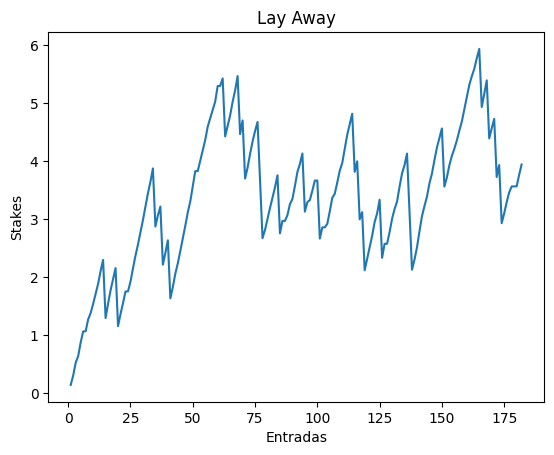

In [18]:
flt = (df_train.VAR06 > 32.005) & (df_train.VAR06 <= 40.365)
df0 = df_train[flt]
df0['Investimento'] = 1
df0 = drop_reset_index(df0)
plot_profit_acu(df0, 'Lay Away')

In [9]:
# df0['Profit'] = np.where((df0['Lay_0x1'] == 1), 0.94, -49)
# df0['Profit_Acu'] = df0['Profit'].cumsum()
# df0[['Profit_Acu']].tail(1)

### Risco de Ruína

In [10]:
# import statistics

# Stake = 0.5
# df0['Profit2'] = Stake * df0['Profit']

# partes = np.array_split(df0, 10)
# df1, df2, df3, df4, df5, df6, df7, df8, df9, df10 = partes

# media_1 = df1['Profit2'].mean()
# media_2 = df2['Profit2'].mean()
# media_3 = df3['Profit2'].mean()
# media_4 = df4['Profit2'].mean()
# media_5 = df5['Profit2'].mean()
# media_6 = df6['Profit2'].mean()
# media_7 = df7['Profit2'].mean()
# media_8 = df8['Profit2'].mean()
# media_9 = df9['Profit2'].mean()
# media_10 = df10['Profit2'].mean()

# lista_medias = [media_1, media_2, media_3, media_4, media_5, media_6, media_7, media_8, media_9, media_10]

# media = statistics.mean(lista_medias)
# desvio_padrao = statistics.stdev(lista_medias)

# banca = 1

# risco_ruina = (np.exp((-2 * media * banca) / (desvio_padrao ** 2))) * 100
# print(f'O Risco de Ruína dessa estratégia é de {round(risco_ruina,2)}%')

### Entradas

In [11]:
# dia = '2024-04-28'
# Jogos_do_Dia = pd.read_csv(f"https://github.com/futpythontrader/YouTube/raw/main/Jogos_do_Dia_FlashScore/{dia}_Jogos_do_Dia_FlashScore.csv")

# flt =
# Entradas = Jogos_do_Dia[flt]
# Entradas = drop_reset_index(Entradas)
# Entradas[['Date','Time','League','Home','Away']]